In [17]:
# ML-2: Predict  the price of uber ride

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [18]:
# Download dataset
import kagglehub
path = kagglehub.dataset_download("yasserh/uber-fares-dataset")

100%|██████████| 7.04M/7.04M [00:00<00:00, 89.9MB/s]

Extracting files...


In [19]:
# Load CSV
import os
csv_path = os.path.join(path, "uber.csv")
df = pd.read_csv(csv_path)

In [20]:
print(df.columns)
print("NULL VALUES:\n", df.isnull().sum())

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='object')
NULL VALUES:
 Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [21]:
# Handle Missing Values

df['dropoff_latitude'] = df['dropoff_latitude'].fillna(
    df['dropoff_latitude'].mean()
)

df['dropoff_longitude'] = df['dropoff_longitude'].fillna(
    df['dropoff_longitude'].mean()
)

print("Missing values after treatment:\n", df.isnull().sum())

Missing values after treatment:
 Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [22]:
# Convert Datetime Column

df['pickup_datetime'] = pd.to_datetime(
    df['pickup_datetime']
)

print("Datatype after transformation:\n", df.dtypes)

Datatype after transformation:
 Unnamed: 0                         int64
key                               object
fare_amount                      float64
pickup_datetime      datetime64[ns, UTC]
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dtype: object


In [23]:
# Remove Unnecessary Columns

df = df.drop(
    ['key', 'pickup_datetime', 'Unnamed: 0'],
    axis = 1
)

df.columns

Index(['fare_amount', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'passenger_count'],
      dtype='object')

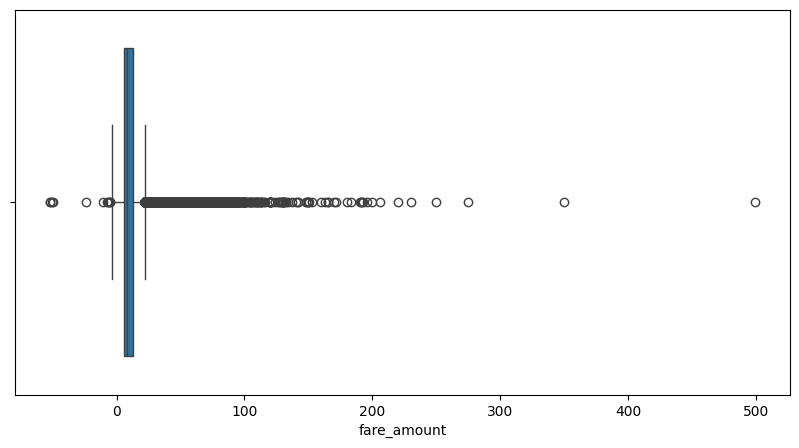

In [24]:
# Handling Outliers

plt.figure(figsize=(10, 5))
sns.boxplot(x=df['fare_amount'])
plt.show()

In [25]:
print("Shape Before:", df.shape)

Shape Before: (200000, 6)


In [26]:
# Remove outliers using the IQR method

df = df[df['fare_amount'] > 0]

q1 = df['fare_amount'].quantile(0.25)
q3 = df['fare_amount'].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

df = df[
    (df['fare_amount'] >= lower_bound) &
    (df['fare_amount'] <= upper_bound)
]

In [27]:
print("Shape After:", df.shape)

Shape After: (182822, 6)


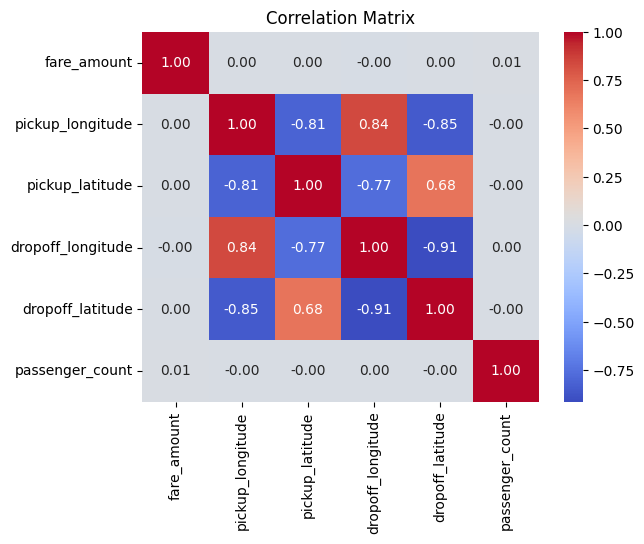

In [28]:
# Correlation

corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Matrix")
plt.show()

In [29]:
# Model Training

X = df.drop(['fare_amount'], axis=1)
y = df['fare_amount']

In [30]:
print(X.dtypes)

pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [32]:
# Applying simple regression , lasso and Ridge model and Evaluate models
models = [LinearRegression(), Ridge(alpha=1.0), Lasso(alpha=0.1)]
names = ['Linear Regression', 'Ridge Regression', 'Lasso Regresssion']

# Model Evaluation
for name, model in zip(names, models):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    print(name)
    print(f"R2 Score: {r2:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"MAE: {mae:.6f}")
    print(f"MSE: {mse:.6f}\n")

Linear Regression
R2 Score: 0.000067
RMSE: 4.175142
MAE: 3.314721
MSE: 17.431807

Ridge Regression
R2 Score: 0.000067
RMSE: 4.175142
MAE: 3.314721
MSE: 17.431807

Lasso Regresssion
R2 Score: -0.000131
RMSE: 4.175554
MAE: 3.314905
MSE: 17.435255

